# Hands-on Lab: Analyzing Historical Stock/Revenue Data and Building a Dashboard

Run **Kernel > Restart & Run All**, then save the notebook before uploading so the outputs are stored.

In [9]:
%pip install -q yfinance pandas requests beautifulsoup4 lxml html5lib matplotlib

Note: you may need to restart the kernel to use updated packages.

In [11]:
from io import StringIO
import yfinance as yf
import pandas as pd
import requests
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt

## Question 1: Tesla stock data

In [12]:
tesla = yf.Ticker('TSLA')
tesla_data = tesla.history(period='max')
tesla_data.reset_index(inplace=True)
tesla_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0


## Helper for cleaning revenue tables

In [13]:
def get_revenue_table(html, keyword):
    """Find the quarterly revenue table in the page and return a clean Date/Revenue dataframe."""
    tables = pd.read_html(StringIO(html))
    chosen = None
    # 1) table whose heading mentions the keyword
    try:
        chosen = pd.read_html(StringIO(html), match=keyword)[0]
    except ValueError:
        pass
    # 2) otherwise first 2-column table whose header mentions 'revenue'
    if chosen is None:
        for t in tables:
            if t.shape[1] == 2 and 'revenue' in ' '.join(map(str, t.columns)).lower():
                chosen = t
                break
    if chosen is None:
        chosen = tables[1]
    df = chosen.iloc[:, :2].copy()
    df.columns = ['Date', 'Revenue']
    df['Revenue'] = df['Revenue'].astype(str).str.replace(r'[$,]', '', regex=True)
    df.dropna(inplace=True)
    df = df[~df['Revenue'].isin(['', 'nan'])]
    df = df.reset_index(drop=True)
    return df

## Question 2: Tesla revenue data

In [14]:
tesla_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm'
html_data = requests.get(tesla_url, headers={'User-Agent': 'Mozilla/5.0'}).text
soup = BeautifulSoup(html_data, 'html.parser')
tesla_revenue = get_revenue_table(html_data, 'Tesla Quarterly Revenue')
tesla_revenue.tail()

,Date,Revenue
48,2010-09-30,31
49,2010-06-30,28
50,2010-03-31,21
51,2009-09-30,46
52,2009-06-30,27


## Question 3: GameStop stock data

In [15]:
gme = yf.Ticker('GME')
gme_data = gme.history(period='max')
gme_data.reset_index(inplace=True)
gme_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2002-02-13 00:00:00-05:00,1.620129,1.693350,1.603296,1.691667,76216000,0.0,0.0
1,2002-02-14 00:00:00-05:00,1.712707,1.716073,1.670626,1.683250,11021600,0.0,0.0
2,2002-02-15 00:00:00-05:00,1.683250,1.687458,1.658001,1.674834,8389600,0.0,0.0
3,2002-02-19 00:00:00-05:00,1.666418,1.666418,1.578047,1.607504,7410400,0.0,0.0
4,2002-02-20 00:00:00-05:00,1.615920,1.662210,1.603296,1.662210,6892800,0.0,0.0


## Question 4: GameStop revenue data

In [16]:
gme_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/stock.html'
html_data_2 = requests.get(gme_url, headers={'User-Agent': 'Mozilla/5.0'}).text
soup = BeautifulSoup(html_data_2, 'html.parser')
gme_revenue = get_revenue_table(html_data_2, 'GameStop Quarterly Revenue')
gme_revenue.tail()

,Date,Revenue
57,2006-01-31,1667
58,2005-10-31,534
59,2005-07-31,416
60,2005-04-30,475
61,2005-01-31,709


## Graph function

In [17]:
def make_graph(stock_data, revenue_data, title):
    stock = stock_data.copy()
    rev = revenue_data.copy()
    stock['Date'] = pd.to_datetime(stock['Date']).dt.tz_localize(None)
    rev['Date'] = pd.to_datetime(rev['Date'])
    rev['Revenue'] = rev['Revenue'].astype(float)
    fig, ax = plt.subplots(2, 1, figsize=(14, 8))
    ax[0].plot(stock['Date'], stock['Close'])
    ax[0].set_title(f'{title} - Historical Share Price')
    ax[0].set_ylabel('Price (USD)')
    ax[1].plot(rev['Date'], rev['Revenue'])
    ax[1].set_title(f'{title} - Historical Revenue')
    ax[1].set_ylabel('Revenue (USD Millions)')
    plt.tight_layout()
    plt.show()

## Question 5: Tesla graph

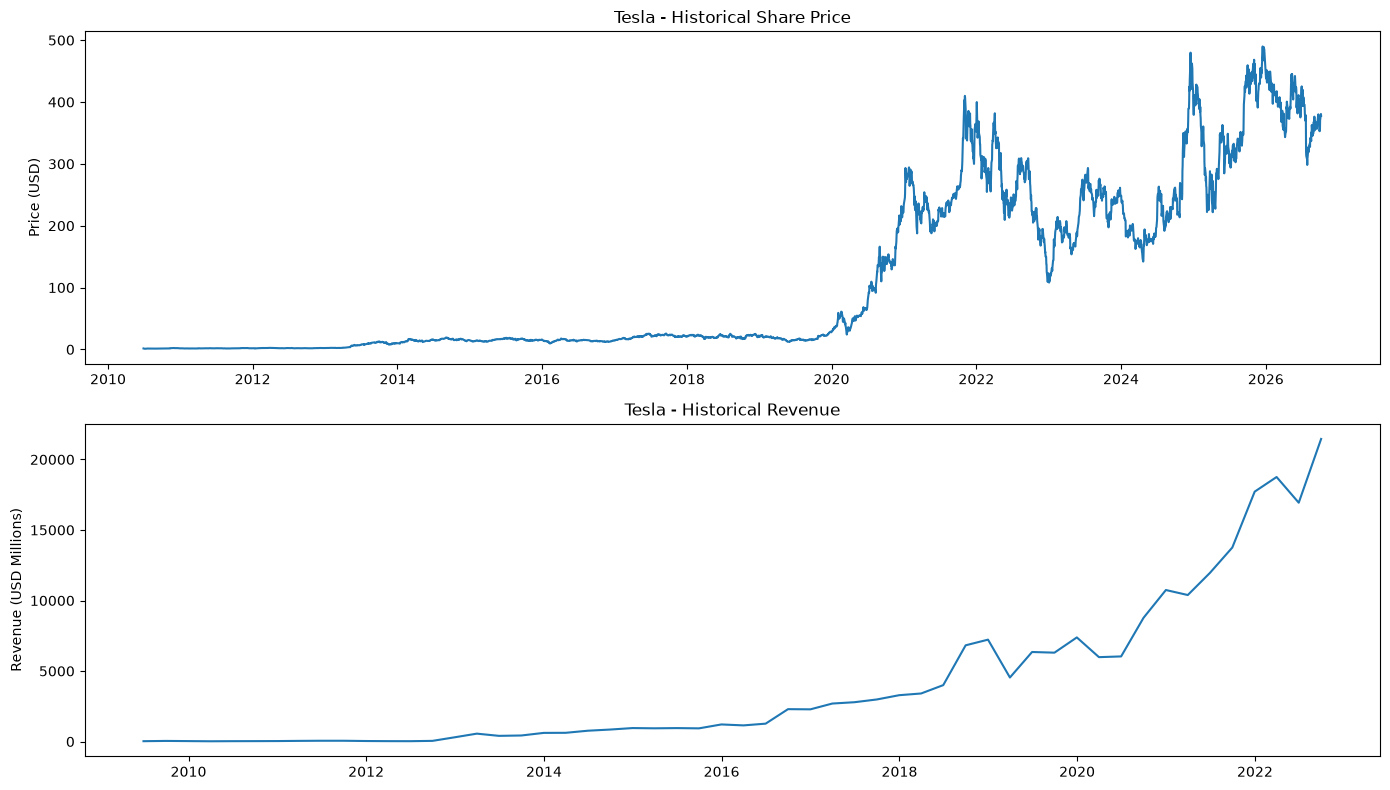

In [18]:
make_graph(tesla_data, tesla_revenue, 'Tesla')

## Question 6: GameStop graph

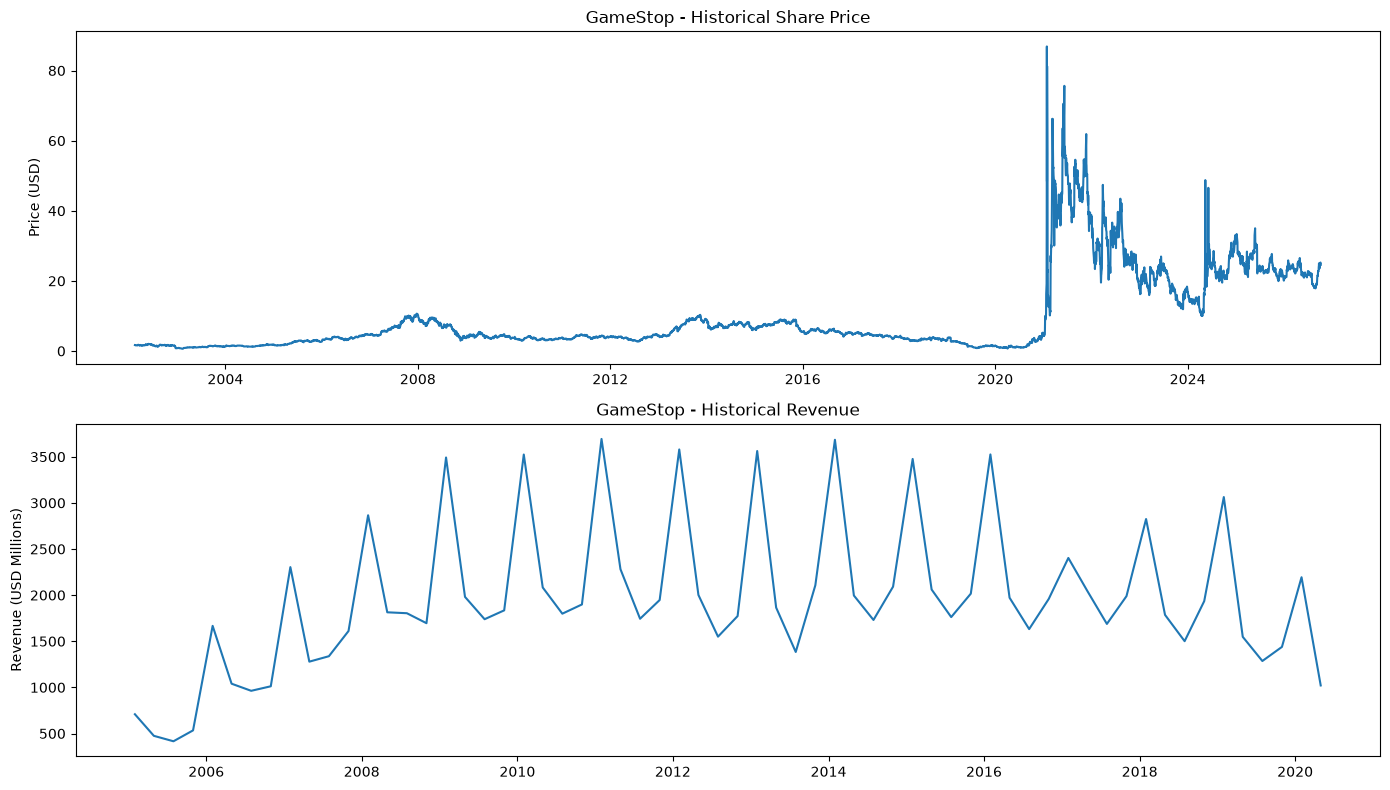

In [19]:
make_graph(gme_data, gme_revenue, 'GameStop')